## 1. Setup

In [2]:
import sklearn, sys
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)
print("Use this same scikit-learn version on the device: pip install scikit-learn==" + sklearn.__version__)

Python 3.13.18 | scikit-learn 1.6.1
Use this same scikit-learn version on the device: pip install scikit-learn==1.6.1
Python 3.13.18 | scikit-learn 1.6.1
Use this same scikit-learn version on the device: pip install scikit-learn==1.6.1


## 2. Get the data


In [5]:
import os, zipfile, glob
USE_DRIVE = True
DRIVE_ZIP = "/content/drive/My Drive/spam sms.zip"
CSV_NAME = "combined_dataset.csv"

if not os.path.exists(CSV_NAME):
    if os.path.exists("spam sms.zip"):
        zip_path = "spam sms.zip"
    elif USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = DRIVE_ZIP
    else:
        from google.colab import files
        zip_path = list(files.upload())[0]
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(".")
print(CSV_NAME, "found:", os.path.exists(CSV_NAME))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
combined_dataset.csv found: True


## 3. Load and explore


In [6]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv(CSV_NAME)
print("Shape:", df.shape)
print(df["target"].value_counts())
df["length"] = df["text"].astype(str).str.len()
print(df.groupby("target")["length"].median().rename("median characters"))
df.sample(5, random_state=1)

Shape: (10961, 2)
target
ham     8555
spam    2406
Name: count, dtype: int64
target
ham     104.0
spam    220.5
Name: median characters, dtype: float64


,target,text,length
2492,spam,80 ( % off mediccationn mediccationns at lowes...,210
619,spam,"offend mosley , govenment don ' t want me to s...",261
9922,ham,Sorry i din lock my keypad.,27
9845,ham,Should i buy him a blackberry bold 2 or torch....,208
8497,ham,Don know:)this week i'm going to tirunelvai da.,47


## 4. Clean


In [7]:
import re

def clean_text(text: str) -> str:
    # Light normalisation so the model sees consistent tokens. (Same as src/detector.py)
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " urltoken ", text)
    text = re.sub(r"[£$₹]|\brs\.?(?=\s?\d)", " moneytoken ", text)
    text = re.sub(r"\b\d{10,13}\b", " phonetoken ", text)
    text = re.sub(r"\b\d{4,6}\b", " shortcodetoken ", text)
    return text

df = df.dropna(subset=["text", "target"])
df["text"] = df["text"].astype(str)
df["key"] = df["text"].str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
before = len(df)
df = df[df["key"].str.len() > 0].drop_duplicates("key").reset_index(drop=True)
print(f"Removed {before - len(df)} empty/duplicate rows -> {len(df)} messages")
df["y"] = (df["target"] == "spam").astype(int)
df["clean"] = df["text"].str[:5000].map(clean_text)
print(df["target"].value_counts())

Removed 738 empty/duplicate rows -> 10223 messages
target
ham     7980
spam    2243
Name: count, dtype: int64


## 5. Train / test split


In [8]:
from sklearn.model_selection import train_test_split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(df["clean"], df["y"], test_size=0.2, stratify=df["y"], random_state=SEED)
print("train", len(X_train), "test", len(X_test))

train 8178 test 2045


## 6. Compare algorithms



In [9]:
import time, pickle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def words():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50000)

def words_and_chars():
    return FeatureUnion([
        ("word", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50000)),
        ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True, max_features=100000)),
    ])

# Every pipeline uses the step names "tfidf" and "clf": the app relies on them.
CANDIDATES = {
    "Naive Bayes (word)":              lambda: Pipeline([("tfidf", words()), ("clf", MultinomialNB(alpha=0.1))]),
    "Logistic Regression (word)":      lambda: Pipeline([("tfidf", words()), ("clf", LogisticRegression(C=10, class_weight="balanced", max_iter=3000))]),
    "Linear SVM (word)":               lambda: Pipeline([("tfidf", words()), ("clf", CalibratedClassifierCV(LinearSVC(C=1, class_weight="balanced"), cv=5))]),
    "Logistic Regression (word+char)": lambda: Pipeline([("tfidf", words_and_chars()), ("clf", LogisticRegression(C=10, class_weight="balanced", max_iter=3000))]),
    "Linear SVM (word+char)":          lambda: Pipeline([("tfidf", words_and_chars()), ("clf", CalibratedClassifierCV(LinearSVC(C=1, class_weight="balanced"), cv=5))]),
    "Random Forest (word)":            lambda: Pipeline([("tfidf", words()), ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
}

rows, fitted = [], {}
for name, make in CANDIDATES.items():
    cv = cross_validate(make(), X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring=["f1", "accuracy"])
    model = make(); t0 = time.time(); model.fit(X_train, y_train); train_s = time.time() - t0
    prob = model.predict_proba(X_test)[:, 1]; pred = (prob >= 0.5).astype(int)
    t0 = time.perf_counter()
    for s in X_test[:300]:
        model.predict_proba([s])
    latency = (time.perf_counter() - t0) / 300 * 1000
    rows.append({"model": name, "cv_f1": cv["test_f1"].mean(), "cv_f1_std": cv["test_f1"].std(), "cv_accuracy": cv["test_accuracy"].mean(),
                 "test_accuracy": accuracy_score(y_test, pred), "test_precision": precision_score(y_test, pred),
                 "test_recall": recall_score(y_test, pred), "test_f1": f1_score(y_test, pred), "test_roc_auc": roc_auc_score(y_test, prob),
                 "train_seconds": train_s, "latency_ms_per_sms": latency, "size_mb": len(pickle.dumps(model)) / 1e6})
    fitted[name] = model
    print(f"{name:34s} CV F1 {rows[-1]['cv_f1']:.4f} | test acc {rows[-1]['test_accuracy']:.4f} | test F1 {rows[-1]['test_f1']:.4f}")

comparison = pd.DataFrame(rows).sort_values("cv_f1", ascending=False).reset_index(drop=True)
comparison.round(4)

Naive Bayes (word)                 CV F1 0.9194 | test acc 0.9682 | test F1 0.9262
Logistic Regression (word)         CV F1 0.9246 | test acc 0.9726 | test F1 0.9364
Linear SVM (word)                  CV F1 0.9289 | test acc 0.9746 | test F1 0.9409
Logistic Regression (word+char)    CV F1 0.9438 | test acc 0.9800 | test F1 0.9535
Linear SVM (word+char)             CV F1 0.9486 | test acc 0.9804 | test F1 0.9546
Random Forest (word)               CV F1 0.8559 | test acc 0.9496 | test F1 0.8730


,model,cv_f1,cv_f1_std,cv_accuracy,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,train_seconds,latency_ms_per_sms,size_mb
0,Linear SVM (word+char),0.9486,0.0086,0.9777,0.9804,0.9723,0.9376,0.9546,0.9981,14.1677,9.2880,9.5412
1,Logistic Regression (word+char),0.9438,0.0094,0.9755,0.9800,0.9722,0.9354,0.9535,0.9979,13.8497,5.0733,5.5442
2,Linear SVM (word),0.9289,0.0111,0.9693,0.9746,0.9606,0.9220,0.9409,0.9943,3.4067,4.3823,3.9763
3,Logistic Regression (word),0.9246,0.0098,0.9672,0.9726,0.9559,0.9176,0.9364,0.9940,7.9226,1.0519,2.3744
4,Naive Bayes (word),0.9194,0.0070,0.9652,0.9682,0.9444,0.9087,0.9262,0.9915,2.3120,2.7477,3.5743
5,Random Forest (word),0.8559,0.0125,0.9431,0.9496,0.9779,0.7884,0.8730,0.9800,43.7832,84.2122,67.3932


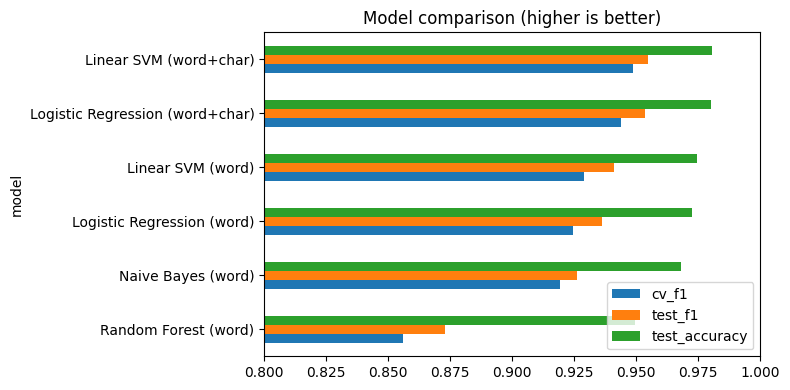

In [10]:
ax = comparison.set_index("model")[["cv_f1", "test_f1", "test_accuracy"]].sort_values("cv_f1").plot.barh(figsize=(8, 4))
ax.set_xlim(0.8, 1.0); ax.set_title("Model comparison (higher is better)"); plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150); plt.show()

## 7. Pick the best model, and why


In [11]:
best_name = comparison.loc[0, "model"]
best = comparison.loc[0]
runner_up = comparison.loc[1]
print(f"Chosen model: {best_name}")
print(f"  CV F1 {best.cv_f1:.4f} ± {best.cv_f1_std:.4f}  vs runner-up {runner_up.model}: {runner_up.cv_f1:.4f}")
print(f"  Test accuracy {best.test_accuracy:.4f}, precision {best.test_precision:.4f}, recall {best.test_recall:.4f}, F1 {best.test_f1:.4f}")
print(f"  {best.latency_ms_per_sms:.1f} ms per SMS, {best.size_mb:.1f} MB")

Chosen model: Linear SVM (word+char)
  CV F1 0.9486 ± 0.0086  vs runner-up Logistic Regression (word+char): 0.9438
  Test accuracy 0.9804, precision 0.9723, recall 0.9376, F1 0.9546
  9.3 ms per SMS, 9.5 MB


## 8. Detailed results for the chosen model

              precision    recall  f1-score   support

         ham     0.9826    0.9925    0.9875      1596
        spam     0.9723    0.9376    0.9546       449

    accuracy                         0.9804      2045
   macro avg     0.9775    0.9651    0.9711      2045
weighted avg     0.9804    0.9804    0.9803      2045



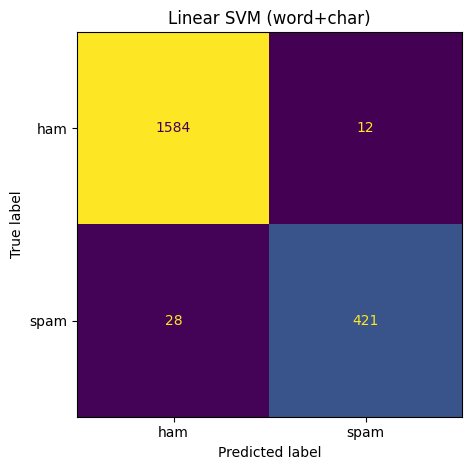

False alarms: 12 of 1596 normal messages | Missed spam: 28 of 449


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
model = fitted[best_name]
prob = model.predict_proba(X_test)[:, 1]; pred = (prob >= 0.5).astype(int)
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=4))
cm = confusion_matrix(y_test, pred); tn, fp, fn, tp = cm.ravel()
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(colorbar=False, values_format="d")
plt.title(best_name); plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()
print(f"False alarms: {fp} of {tn + fp} normal messages | Missed spam: {fn} of {fn + tp}")

In [20]:
examples = [
    "Dear customer, your SBI account KYC is pending and will be blocked today. Update now: http://sbi-kyc-update.xyz",
    "Congratulations! You have won Rs 25,00,000 in KBC lottery. Call 9876543210 to claim your prize.",
    "Your electricity connection will be disconnected tonight at 9.30pm. Contact officer 8123456789 immediately.",
    "Your OTP for login is 482910. Do not share it with anyone. -HDFC Bank",
    "Rs 2,000 credited to your account via UPI from Ravi. Avl bal Rs 15,230.",
    "Hi amma, I'll reach home by 7. Keep dinner ready.",
    "Meeting moved to 3pm tomorrow, see you in the lab",
    "I love your smile"
    "You won a scooty in offer, please click the above link http://hiiyourareamenahha,com"
]
for e in examples:
    p = model.predict_proba([clean_text(e)])[0, 1]
    print(f"{'SCAM' if p >= 0.5 else 'safe':4s} {p:.2f}  {e[:80]}")

SCAM 0.89  Dear customer, your SBI account KYC is pending and will be blocked today. Update
SCAM 1.00  Congratulations! You have won Rs 25,00,000 in KBC lottery. Call 9876543210 to cl
SCAM 0.88  Your electricity connection will be disconnected tonight at 9.30pm. Contact offi
SCAM 0.59  Your OTP for login is 482910. Do not share it with anyone. -HDFC Bank
SCAM 0.95  Rs 2,000 credited to your account via UPI from Ravi. Avl bal Rs 15,230.
safe 0.00  Hi amma, I'll reach home by 7. Keep dinner ready.
safe 0.00  Meeting moved to 3pm tomorrow, see you in the lab
SCAM 0.95  I love your smileYou won a scooty in offer, please click the above link http://h


## 9. Save in the app's format and download


In [21]:
import joblib, json, shutil
final = CANDIDATES[best_name]().fit(df["clean"], df["y"])
os.makedirs("sms_model_artifacts", exist_ok=True)
joblib.dump({"pipeline": final, "threshold": 0.5, "model_name": best_name, "sklearn_version": sklearn.__version__},
            "sms_model_artifacts/scam_detector.joblib", compress=3)

metrics = {
    "dataset": {"name": "combined_dataset.csv (spam_sms.zip)", "messages": int(len(df)), "spam": int(df.y.sum()),
                "ham": int((1 - df.y).sum()), "test_size": int(len(y_test))},
    "model": best_name,
    "threshold": 0.5,
    "holdout_test_20pct": {"accuracy": round(accuracy_score(y_test, pred), 4), "precision": round(precision_score(y_test, pred), 4),
                           "recall": round(recall_score(y_test, pred), 4), "f1": round(f1_score(y_test, pred), 4),
                           "roc_auc": round(roc_auc_score(y_test, prob), 4),
                           "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}},
    "cv_5fold_f1": {"mean": round(float(best.cv_f1), 4), "std": round(float(best.cv_f1_std), 4)},
    "latency_ms_per_sms": round(float(best.latency_ms_per_sms), 2),
    "model_file_kb": round(os.path.getsize("sms_model_artifacts/scam_detector.joblib") / 1024, 1),
    "comparison": comparison.round(4).to_dict(orient="records"),
    "sklearn_version": sklearn.__version__,
}
json.dump(metrics, open("sms_model_artifacts/metrics.json", "w"), indent=2)
comparison.round(4).to_csv("sms_model_artifacts/model_comparison.csv", index=False)
for f in ["model_comparison.png", "confusion_matrix.png"]:
    shutil.copy(f, "sms_model_artifacts/")
shutil.make_archive("sms_model_artifacts", "zip", "sms_model_artifacts")
print(os.listdir("sms_model_artifacts"))
try:
    from google.colab import files
    files.download("sms_model_artifacts.zip")
except ImportError:
    print("Not in Colab: sms_model_artifacts.zip is in the current folder")

['scam_detector.joblib', 'model_comparison.csv', 'metrics.json', 'model_comparison.png', 'confusion_matrix.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Deploy
1. Unzip `sms_model_artifacts.zip`.
2. Copy `scam_detector.joblib` and `metrics.json` into `sms-scam-detector/models/` (replacing the old ones).
3. On the device: `pip install scikit-learn==<version printed in step 1>`, then `streamlit run app/app.py`.

The app, Llama explainer and benchmark script work unchanged.